# 02 — Diagnostics: is the fit lying to us?

**Status:** Day 4 — the full reading. Wednesday fitted the model; today we
interrogate it. Every section ends with a *verdict* and, where relevant, a
candidate spec change for Friday.

The one number so far (5-fold CV, out-of-fold):

| spec | CV RMSE (dollars) | CV RMSLE (log) |
|---|---|---|
| v1_full_pipeline | **$77,885** | **0.15453** |

RMSLE 0.15 ≈ a typical prediction off by 15% on the log scale. RMSE in dollars
looks alarming ($77k) because mansions dominate squared dollar errors — the
skew we tamed in the target, reappearing in the metric.

## 1. Fit on all of train

The model we diagnose is fitted on every training house (the CV number came
from unseen houses; this fit is for inspection).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from house_prices.data import load_train, load_test
from house_prices.features import build_features, align_columns
from house_prices.train import fit_spec

train = load_train()
model, metrics = fit_spec(train)
print(f"CV RMSE ${metrics['rmse']:,.0f}   CV RMSLE {metrics['rmsle']:.5f}")

CV RMSE $77,885   CV RMSLE 0.15453


## 2. Residuals vs fitted — the first lie-detector

**Residual** = actual − predicted (log space; 0.10 ≈ 10% off). We want random
scatter around zero: no fan, no curve, no loners.

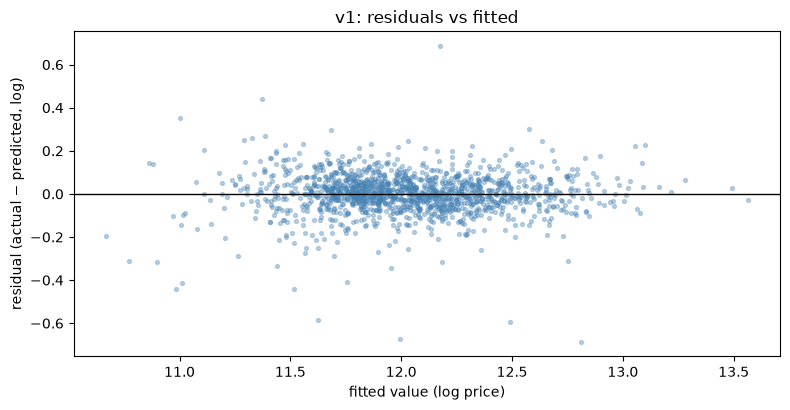

In [2]:
X, y = build_features(train)
fitted = model.predict(X)
resid = np.asarray(y) - fitted

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(fitted, resid, s=8, alpha=0.35, color="steelblue")
ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("fitted value (log price)")
ax.set_ylabel("residual (actual − predicted, log)")
ax.set_title("v1: residuals vs fitted")
plt.tight_layout()

**Verdict — no dramatic fan.** Spread in the low-fitted third (sd 0.109)
≈ the high-fitted third (sd 0.095); correlation of |residual| with fitted is
only −0.11. The log transforms did their job — errors are roughly equally
noisy across cheap and expensive houses. Not a Friday priority.

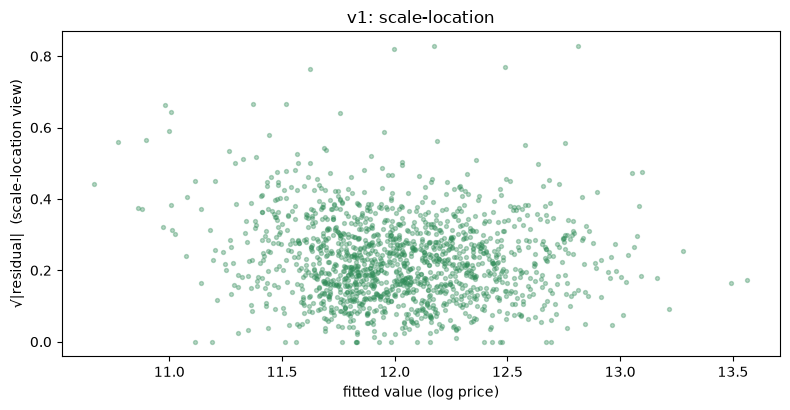

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(fitted, np.sqrt(np.abs(resid)), s=8, alpha=0.35, color="seagreen")
ax.set_xlabel("fitted value (log price)")
ax.set_ylabel("√|residual|  (scale-location view)")
ax.set_title("v1: scale-location")
plt.tight_layout()

## 3. Normality — Q–Q plot

OLS assumes residuals are ~normal mostly so that p-values and intervals are
honest; for pure prediction, mild violation is survivable. The Q–Q plot:
points on the diagonal = normal; sagging ends = heavy tails.

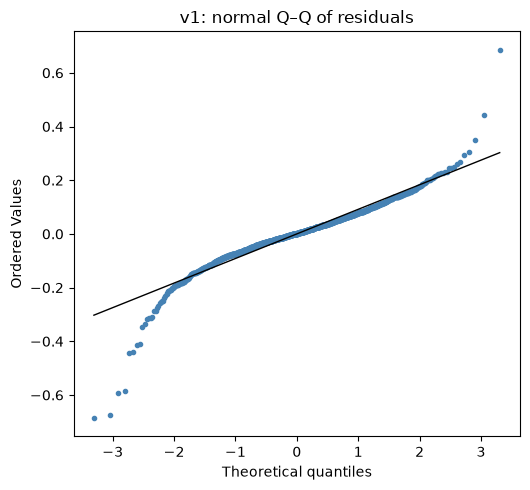

In [4]:
fig, ax = plt.subplots(figsize=(5.4, 5))
stats.probplot(resid, dist="norm", plot=ax)
ax.get_lines()[0].set(marker="o", ms=3, color="steelblue")
ax.get_lines()[1].set(color="black", linewidth=1)
ax.set_title("v1: normal Q–Q of residuals")
plt.tight_layout()

**Verdict — heavy tails, not a broken shape.** Residual skew −0.82 (mild
left lean) but kurtosis 8.4 (normal = 3): a few predictions are *way* off and
drag the tails. Shapiro–Wilk p ≈ 1e-27 "rejects normality", but at n=1460 it
rejects almost anything — with big data, look at the effect size (the plot),
not the p-value. The tails are the outliers of section 4 — same story.

## 4. Leverage & influence — who yanks the line?

**Leverage** hᵢ measures how unusual a house's *inputs* are (a house alone in
its own category has maximum room to pull). **Cook's distance** combines
leverage with a big residual: the houses we'd miss most if deleted.
Computed here from first principles (hat matrix), no statsmodels needed —
X₁ = [1, X], h = diag(X₁(X₁ᵀX₁)⁻¹X₁ᵀ), D = (e²/p·MSE)·h/(1−h)².

In [5]:
X1 = np.column_stack([np.ones(len(X)), X.to_numpy(float)])
A = np.linalg.pinv(X1.T @ X1)
h = np.sum((X1 @ A) * X1, axis=1)
p = X1.shape[1]
mse = np.mean(resid**2)
cook = (resid**2 / (p * mse)) * (h / (1 - h) ** 2)

print(f"params p={p}; leverage max={h.max():.3f} (suspicious: 1.0 = model can fit that point exactly)")
print(f"Cook's D > 4/n ({4/len(X):.4f}): {(cook > 4/len(X)).sum()} houses; top two: {np.sort(cook)[-2:].round(3)}")

params p=255; leverage max=1.000 (suspicious: 1.0 = model can fit that point exactly)
Cook's D > 4/n (0.0027): 122 houses; top two: [0.587 0.587]


**A leverage of 1.000 is a red flag worth understanding.** It means at
least one house is *perfectly self-fitted* — the model can nail it exactly
because it owns a lever no other house touches. Prime suspects: one-hot
columns for categories that appear once. Check the roof materials driving
the biggest coefficients…

In [6]:
for c in ["ClyTile", "Membran", "Metal", "WdShngl"]:
    n = (train["RoofMatl"] == c).sum()
    print(f"RoofMatl_{c:>8}: {n} house(s) in train")

RoofMatl_ ClyTile: 1 house(s) in train
RoofMatl_ Membran: 1 house(s) in train
RoofMatl_   Metal: 1 house(s) in train
RoofMatl_ WdShngl: 6 house(s) in train


**Found it.** `ClyTile`, `Membran`, `Metal` appear exactly **once** each.
Their dummy column is a private lever — the model gives that one house its
own coefficient and fits it perfectly (h=1). That's not real-estate signal;
it's memorization.

Now meet the two Cook's-D leaders rather than auto-deleting them:

In [7]:
cols = ["Id", "Neighborhood", "OverallQual", "GrLivArea", "YearBuilt", "SalePrice"]
print(train[train["Id"].isin([826, 524])][cols].to_string(index=False))
big = train[train["GrLivArea"] > 4500]
print(f"\nother 4500+ sqft houses: median price ${big['SalePrice'].median():,.0f} (n={len(big)})")
print(f"quality-10 houses overall: median ${train[train['OverallQual']==10]['SalePrice'].median():,.0f}")

 Id Neighborhood  OverallQual  GrLivArea  YearBuilt  SalePrice
524      Edwards           10       4676       2007     184750
826      NridgHt           10       2084       2007     385000

other 4500+ sqft houses: median price $172,375 (n=2)
quality-10 houses overall: median $432,390


**Verdict — outliers are *real houses*, and the cause is fixable.** Id 524
(4,676 sq ft, quality 10, $184,750) looks wrong until you see other huge
houses also sit near $172k median — big-but-cheap is a genuine pattern in
Ames (estate homes on cheaper land). Id 826 is mildly cheap for quality 10.
Deleting honest houses to flatter CV is cheating ourselves; the real defect
is the **singleton categories**. Friday spec candidate:

- **S1 — collapse rare categories:** any category with < 10 houses → `Other`
  *before* one-hot. Kills the h=1.0 levers and the nonsense roof coefficients
  in one move.
- **S2 — outlier sensitivity check (diagnostic only):** refit without Ids
  {826, 524} and see how much CV moves; whatever it teaches, we keep the
  houses.

## 5. Coefficient sanity — does the model talk like a realtor?

In log-space, a coefficient on a logged feature is an *elasticity* (×1.10 per
+10% of feature); on an ordinal like OverallQual it's ≈ % price per point.

In [8]:
coef = pd.Series(model.coef_, index=X.columns)
table = pd.DataFrame({"coef": coef.round(3)})
table["abs"] = table["coef"].abs()
print("largest |coefficients| (what dominates the model today):")
print(table.sort_values("abs", ascending=False).head(8).drop(columns="abs"))
print("\nsignal we expected (Monday's top correlates):")
print(table.loc[["OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF"]].drop(columns="abs"))

largest |coefficients| (what dominates the model today):
                   coef
RoofMatl_ClyTile -2.342
Condition2_PosN  -0.707
RoofMatl_Membran  0.567
RoofMatl_Metal    0.393
RoofMatl_WdShngl  0.376
Condition2_PosA   0.361
MSZoning_C (all) -0.353
Condition2_RRAe  -0.313

signal we expected (Monday's top correlates):
              coef
OverallQual  0.044
GrLivArea    0.001
GarageCars   0.019
TotalBsmtSF  0.000


**Verdict — the model's loudest voices are one-house categories.**
`RoofMatl_ClyTile` at **−2.34** means "having the only clay-tile roof in town
cuts predicted price by e⁻²·³⁴ ≈ 90%" — absurd, and it's literally one house.
Meanwhile the real signal is sane and modest: **OverallQual +0.044/point
(≈ +4.5% per quality point)**, garage capacity and living area positive, all
as a buyer would expect. The fix list for Friday writes itself:

- **S1** (from section 4) rare-category collapse — makes the top table honest.
- **S3 — Monday's collinearity drops:** one from each twin pair —
  (GarageCars | GarageArea), (TotalBsmtSF | 1stFlrSF), (GrLivArea | TotRmsAbvGrd).

## 6. Candidate specs for Friday

| # | spec | motivated by | hypothesis |
|---|---|---|---|
| S1 | rare-category collapse (<10 → Other) | h=1.0 levers, absurd roof coefficients | CV improves; coefficients readable |
| S2 | drop {826, 524} (sensitivity only) | top Cook's D = 0.59 each | measures their pull; house-keeping decision after |
| S3 | drop one collinear twin from each pair | Monday r≥0.82 pairs | steadier coefficients, small CV gain |

Friday runs each through the same 5-fold CV, appends to `results/runs.csv`,
and the champion must arrive with a written reason — not just the lowest number.